In [929]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [930]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

# Cleaning

Situazione iniziale

In [931]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 100 to 101
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Timestamp           150 non-null    object 
 1   age                 150 non-null    int64  
 2   sex                 150 non-null    object 
 3   weight              150 non-null    float64
 4   height              150 non-null    int64  
 5   train_years         150 non-null    object 
 6   train_week          150 non-null    int64  
 7   z2_train_week       148 non-null    float64
 8   fartelk_train_week  136 non-null    float64
 9   power_train_week    118 non-null    float64
 10  avg_km_week         150 non-null    object 
 11  sleep_hour          150 non-null    int64  
 12  vo2_max             150 non-null    object 
 13  min_heart_rate      150 non-null    int64  
 14  max_heart_rate      150 non-null    int64  
 15  cadence             141 non-null    object 
 16  hm_time    

In [932]:
print(f"Numero di righe: {df.shape[0]}")
print(f"Numero di colonne: {df.shape[1]}")

Numero di righe: 150
Numero di colonne: 18


In [933]:
df.head()

,Timestamp,age,sex,weight,height,train_years,train_week,z2_train_week,fartelk_train_week,power_train_week,avg_km_week,sleep_hour,vo2_max,min_heart_rate,max_heart_rate,cadence,hm_time,mid_hm_time
100,01/07/2025 00:07:41,18,Maschio,83.0,187,6,4,1.0,2.0,1.0,30,9,59,59,180,175,1:40:32,00:46:57
99,01/07/2025 00:41:15,27,Maschio,68.0,170,2,6,2.0,2.0,3.0,70,6,63,53,191,180,1:22:47,37:30
98,01/07/2025 08:48:29,23,Maschio,77.0,181,1,2,1.0,1.0,2.0,25,6,50,45,196,165,1:52:00,00:55:00
97,01/07/2025 10:11:15,28,Maschio,75.0,176,2,3,2.0,1.0,2.0,20,7,49,50,196,165,01:39:57,00:49:44
96,01/07/2025 11:59:10,27,Maschio,99.0,188,1,3,1.0,1.0,1.0,10,8,40,69,190,152,2:35:00,1:10:00


In [934]:
df.drop(columns=['Timestamp'], inplace=True)

In [935]:
df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})
df['sex'] = df['sex'].astype(int)

C:\Users\Gabri\AppData\Local\Temp\ipykernel_500\160705813.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [936]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , '10 in su': 11})
df['train_years'] = df['train_years'].astype(int)

In [937]:
df.z2_train_week = df.z2_train_week.fillna(0).astype(int)
df.fartelk_train_week = df.fartelk_train_week.fillna(0).astype(int)
df.power_train_week = df.power_train_week.fillna(0).astype(int)

In [938]:
df['avg_km_week'] = df['avg_km_week'].replace({'Più di 80': 85})
df['avg_km_week'] = df['avg_km_week'].astype(int)

Creo la colonna per avere i tempi in secondi

In [939]:
def time_to_seconds(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 3600 + m * 60 + s

# Applica la funzione
df['hm_time_sec'] = df['hm_time'].apply(time_to_seconds)
df['mid_hm_time_sec'] = df['mid_hm_time'].apply(time_to_seconds)

Creo la colonna per avere i tempi in minuti

In [940]:
def time_to_minutes(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 60 + m + s / 60

df['hm_time_min'] = df['hm_time'].apply(time_to_minutes)
df['mid_hm_time_min'] = df['mid_hm_time'].apply(time_to_minutes)

df.drop(columns=['hm_time', 'mid_hm_time'], inplace=True)


Elimino outlier troppo grandi

In [941]:
df = df[df['hm_time_min'] < 140]

Colonne con troppi valori null

In [942]:
df.drop(columns=['cadence', 'vo2_max'], inplace=True)

Controlliamo se ci sono valori null nel dataframe

In [943]:
df.isnull().values.any()

np.False_

Stampiamo i risultati della fase di cleaning

In [944]:
print(f"Numero di righe nel DataFrame: {len(df)}")
print(f"Numero di colonne nel DataFrame: {len(df.columns)}")

Numero di righe nel DataFrame: 145
Numero di colonne nel DataFrame: 17


Controllo finale 

In [945]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 100 to 102
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 145 non-null    int64  
 1   sex                 145 non-null    int64  
 2   weight              145 non-null    float64
 3   height              145 non-null    int64  
 4   train_years         145 non-null    int64  
 5   train_week          145 non-null    int64  
 6   z2_train_week       145 non-null    int64  
 7   fartelk_train_week  145 non-null    int64  
 8   power_train_week    145 non-null    int64  
 9   avg_km_week         145 non-null    int64  
 10  sleep_hour          145 non-null    int64  
 11  min_heart_rate      145 non-null    int64  
 12  max_heart_rate      145 non-null    int64  
 13  hm_time_sec         145 non-null    int64  
 14  mid_hm_time_sec     145 non-null    int64  
 15  hm_time_min         145 non-null    float64
 16  mid_hm_time

---

# EDA

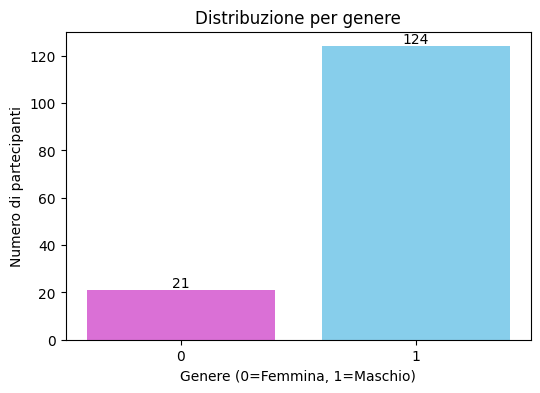

In [946]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

# Aggiungi il numero sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


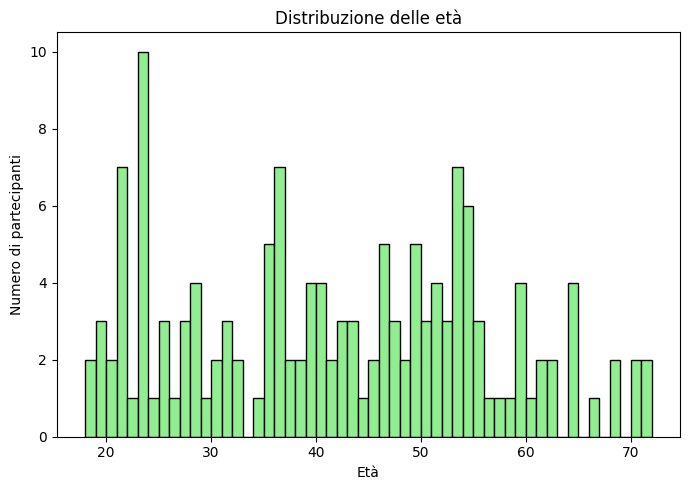

Età media: 41.57931034482758


In [947]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max() + 2), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()

print("Età media:", df['age'].mean())


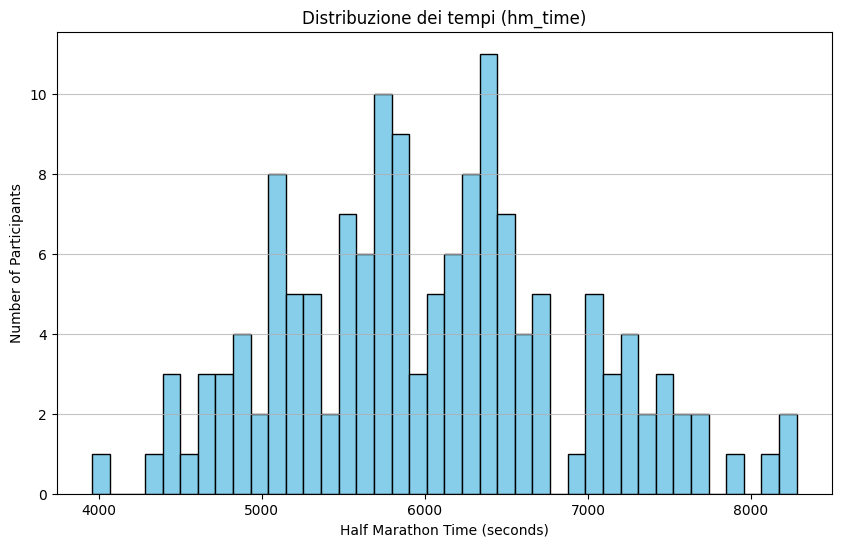

In [948]:
hm_time_sec = df['hm_time_sec']
plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (seconds)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

Possiamo notare che la distribuzione dei tempi segue una distribuzione normale

In [949]:
print("Tempo medio (min):", df.hm_time_min.mean())
print("Deviazione standard (min):", df.hm_time_min.std())

Tempo medio (min): 100.49827586206897
Deviazione standard (min): 14.75482288332982


Deviazione standard alta, fa intuire che sono state ricevute risposte da runner esperti e da amatori. Non è un gruppo omogeneo.

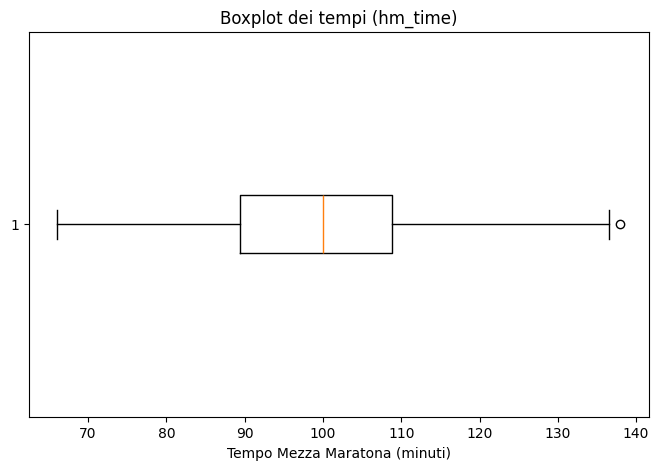

In [950]:
plt.figure(figsize=(8, 5))
plt.boxplot(df.hm_time_min, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time)')
plt.show()

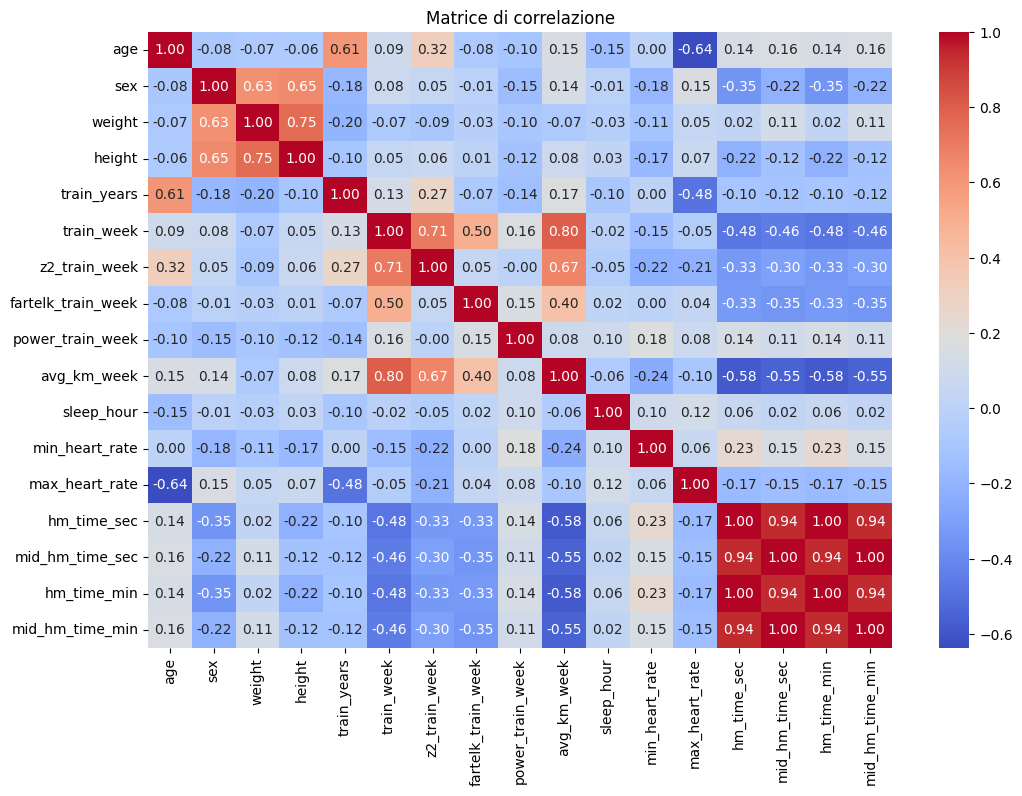

In [951]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True)
plt.title("Matrice di correlazione")
plt.show()


Dalla matrice di correlazione emerge che i fattori più associati alla performance sono il chilometraggio medio settimanale e la frequenza degli allenamenti, oltre anche gli anni di esperienza. Le variabili fisiologiche, invece,  hanno correlazioni più deboli sul tempo finale.

### Z2 vs Power

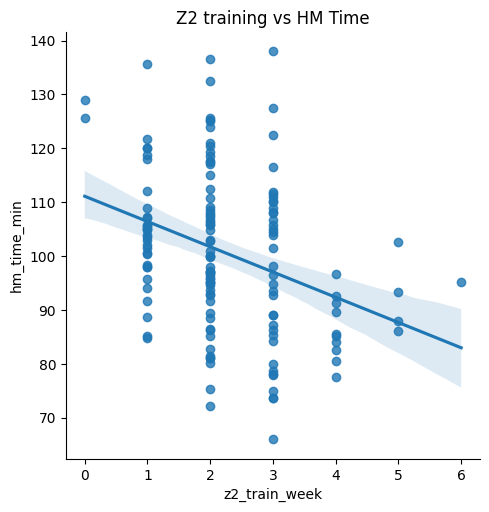

In [952]:
# Scatter plot + regressione
sns.lmplot(data=df, x='z2_train_week', y='hm_time_min')
plt.title("Z2 training vs HM Time")
plt.show()

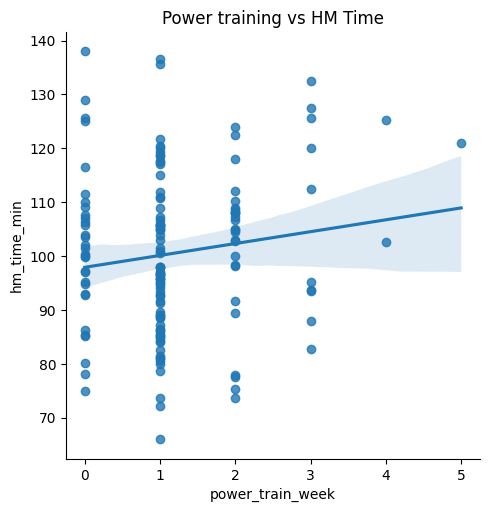

In [953]:
sns.lmplot(data=df, x='power_train_week', y='hm_time_min')
plt.title("Power training vs HM Time")
plt.show()

In [954]:
from scipy.stats import pearsonr

# Correlazioni Pearson
r_z2, _ = pearsonr(df['z2_train_week'], df['hm_time_min'])
r_power, _ = pearsonr(df['power_train_week'], df['hm_time_min'])

print(f"Correlazione Z2-HM Time: {r_z2:.2f}")
print(f"Correlazione Power-HM Time: {r_power:.2f}")

Correlazione Z2-HM Time: -0.33
Correlazione Power-HM Time: 0.14


Z2: La correlazione negativa indica che più allenamenti in zona 2 sono associati a tempi finali migliori.

Power: La correlazione quasi nulla significa che gli allenamenti di potenza non hanno un’associazione chiara con il tempo finale in mezza maratona.

In [955]:
r_power10k, _ = pearsonr(df['power_train_week'], df['mid_hm_time_min'])
print(f"Correlazione Power vs Tempo 10km: {r_power10k:.2f}")

Correlazione Power vs Tempo 10km: 0.11


### Ore di sonno

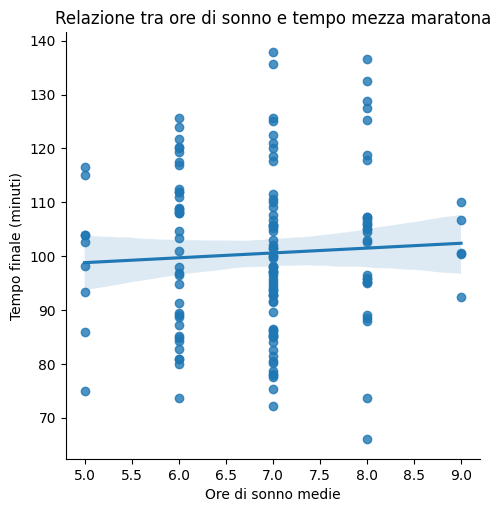

Coefficiente di correlazione: 0.055931507340495214


In [956]:
sns.lmplot(x='sleep_hour', y='hm_time_min', data=df)
plt.title('Relazione tra ore di sonno e tempo mezza maratona')
plt.xlabel('Ore di sonno medie')
plt.ylabel('Tempo finale (minuti)')
plt.show()

corr = df['sleep_hour'].corr(df['hm_time_min'])
print(f"Coefficiente di correlazione: {corr}")

Non c'è nessuna relazione diretta forte tra il sonno dell'atleta e il suo tempo finale in gara. 
Atleti con lo stesso sonno ottengono tempi molto diversi.

### KDE - Density Plot (Group By Sex)

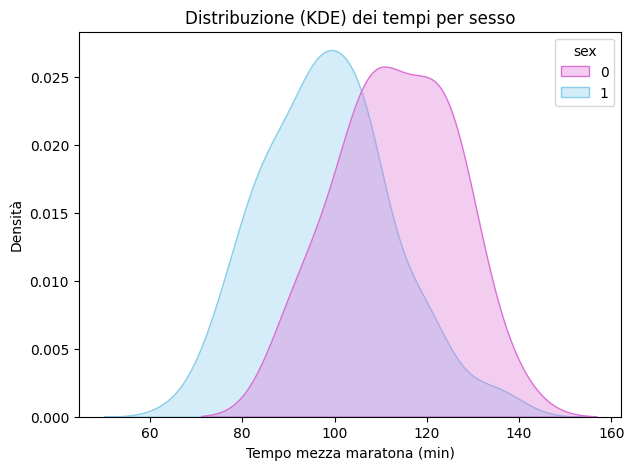

In [957]:
plt.figure(figsize=(7,5))
sns.kdeplot(
    data=df, x='hm_time_min', hue='sex',
    common_norm=False, fill=True, alpha=0.35,
    palette=['orchid', 'skyblue']
)
plt.title('Distribuzione (KDE) dei tempi per sesso')
plt.xlabel('Tempo mezza maratona (min)')
plt.ylabel('Densità')
plt.show()

###  Analisi per quartili

Prendiamo il primo e l'ultimo quartile per analizzarne le differenze

In [958]:
q1 = df['hm_time_min'].quantile(0.25)
q3 = df['hm_time_min'].quantile(0.75)

# Creazione gruppi
df['quartile_group'] = pd.cut(
    df['hm_time_min'],
    bins=[df['hm_time_min'].min()-0.1, q1, q3, df['hm_time_min'].max()+0.1],
    labels=['Q1', 'Q2-Q3', 'Q4']
)

In [959]:
q1_df = df[df['quartile_group'] == 'Q1']
q4_df = df[df['quartile_group'] == 'Q4']

In [960]:
print("Q1 - Media Tempo Finale:", q1_df.hm_time_min.mean())
print("Q4 - Media Tempo Finale:", q4_df.hm_time_min.mean())

Q1 - Media Tempo Finale: 82.1990990990991
Q4 - Media Tempo Finale: 119.91388888888888


In [961]:
print("Q1 - Media km settimanali:", q1_df.avg_km_week.mean())
print("Q4 - Media km settimanali:", q4_df.avg_km_week.mean())


Q1 - Media km settimanali: 59.32432432432432
Q4 - Media km settimanali: 31.52777777777778


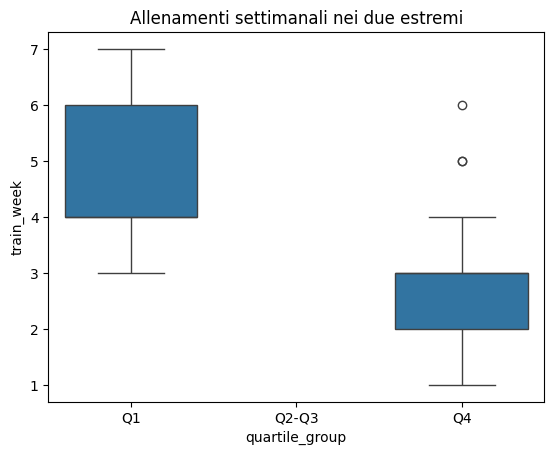

In [962]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='train_week')
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

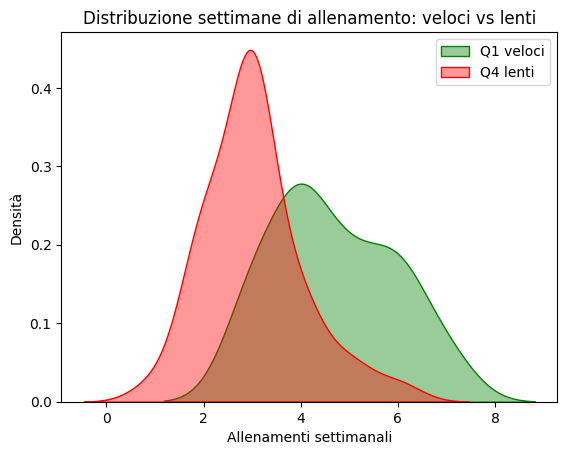

In [963]:
sns.kdeplot(data=q1_df, x='train_week', label='Q1 veloci', fill=True, alpha=0.4, color='green')
sns.kdeplot(data=q4_df, x='train_week', label='Q4 lenti', fill=True, alpha=0.4, color='red')

plt.title('Distribuzione settimane di allenamento: veloci vs lenti')
plt.xlabel('Allenamenti settimanali')
plt.ylabel('Densità')
plt.legend()
plt.show()

Dal grafico si nota una differenza chiara nella frequenza di allenamento tra i due quartili presi in esame.
I runner più veloci mostrano una distribuzione centrata su 4–6 allenamenti settimanali, mentre i più lenti si concentrano intorno a 2 sedute settimanali. 
Il numero di allenamenti risulta quindi una variabile molto importante per la performance finale.

---

# Prevision

### Splitting

In [964]:
from sklearn import model_selection

data_train, data_test = model_selection.train_test_split(df, test_size=0.2, random_state=42)

Il dataset è stato diviso con una percentuale dell'80% per il train e il restante 205 come test.
Avendo poche tuple, è stato deciso di non utilizzare il validation in modo da avere più informazioni possibili nella fase di train.

In [965]:
# Train set
X_train = data_train[['age','sex','weight','height' ,'avg_km_week', 'train_years', 
                'train_week','z2_train_week', 'fartelk_train_week', 'power_train_week',
                'sleep_hour','min_heart_rate','max_heart_rate']]

y_train = data_train['hm_time_min']


# Test set
X_test = data_test[['age','sex','weight','height','avg_km_week','train_years',
                  'train_week','z2_train_week','fartelk_train_week',
                  'power_train_week','sleep_hour','min_heart_rate','max_heart_rate']]

y_test = data_test['hm_time_min']

LinearRegression fits a linear model with coefficients w = (w1, …, wp) to minimize the residual sum of squares between the observed targets in the dataset, and the targets predicted by the linear approximation.

Fonte: scikit-learn.org

In [966]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Creazione modello
model = LinearRegression()
model.fit(X_train, y_train)

# Predizioni
y_pred = model.predict(X_test)

# Metriche corrette
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")


MSE  : 87.47
RMSE : 9.35
MAE  : 7.59
R²   : 0.5579


In [967]:
from sklearn.svm import SVR

# Creazione modello SVM (kernel RBF di default)
svm_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)

# Addestramento
svm_model.fit(X_train, y_train)

# Predizioni
y_pred = svm_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} sec")
print(f"MAE  : {mae:.2f} sec")
print(f"R²   : {r2:.4f}")

MSE  : 210.73
RMSE : 14.52 sec
MAE  : 11.70 sec
R²   : -0.0652


In [968]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

pipe = make_pipeline(StandardScaler(), SVR())

param_grid = {
    'svr__C': [1, 10, 100, 1000],
    'svr__gamma': [0.0001, 0.001, 0.01, 0.1, 'scale'],
    'svr__epsilon': [10, 50, 100, 300, 500]
}

grid = GridSearchCV(pipe, param_grid, scoring='neg_mean_absolute_error', cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Migliori parametri:", grid.best_params_)

y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} sec")
print(f"MAE  : {mae:.2f} sec")
print(f"R²   : {r2:.4f}")


Migliori parametri: {'svr__C': 100, 'svr__epsilon': 10, 'svr__gamma': 0.01}
MSE  : 77.62
RMSE : 8.81 sec
MAE  : 7.11 sec
R²   : 0.6077


In [969]:
# Pipeline: scaling + SVR polinomiale
svr_poly = make_pipeline(
    StandardScaler(),
    SVR(kernel='poly', degree=3, C=1000, gamma=0.01, epsilon=100)
)

# Addestramento
svr_poly.fit(X_train, y_train)

# Predizioni
y_pred_poly = svr_poly.predict(X_test)

# Metriche
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print(f"[SVR Poly] MSE  : {mse_poly:.2f}")
print(f"[SVR Poly] RMSE : {rmse_poly:.2f} sec")
print(f"[SVR Poly] MAE  : {mae_poly:.2f} sec")
print(f"[SVR Poly] R²   : {r2_poly:.4f}")

[SVR Poly] MSE  : 200.75
[SVR Poly] RMSE : 14.17 sec
[SVR Poly] MAE  : 11.58 sec
[SVR Poly] R²   : -0.0147


In [970]:
from sklearn.ensemble import RandomForestRegressor

# Modello Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,    # numero di alberi
    max_depth=None,      # nessun limite alla profondità
    random_state=42,
    n_jobs=-1
)

# Addestramento
rf_model.fit(X_train, y_train)

# Predizioni
y_pred = rf_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} sec")
print(f"MAE  : {mae:.2f} sec")
print(f"R²   : {r2:.4f}")


MSE  : 119.81
RMSE : 10.95 sec
MAE  : 8.03 sec
R²   : 0.3944


In [971]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)

# Addestramento
gbr.fit(X_train, y_train)

# Predizioni
y_pred_gbr = gbr.predict(X_test)

# Metriche
mse_gbr = mean_squared_error(y_test, y_pred_gbr)
rmse_gbr = np.sqrt(mse_gbr)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
r2_gbr = r2_score(y_test, y_pred_gbr)

print(f"[GBR] MSE  : {mse_gbr:.2f}")
print(f"[GBR] RMSE : {rmse_gbr:.2f} sec")
print(f"[GBR] MAE  : {mae_gbr:.2f} sec")
print(f"[GBR] R²   : {r2_gbr:.4f}")


[GBR] MSE  : 127.02
[GBR] RMSE : 11.27 sec
[GBR] MAE  : 8.31 sec
[GBR] R²   : 0.3579


In [972]:
import xgboost as xgb

# Creazione modello XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=500,       # numero di alberi
    learning_rate=0.05,     # tasso di apprendimento
    max_depth=6,            # profondità massima
    subsample=0.8,          # percentuale di campioni usati per ogni albero
    colsample_bytree=0.8,   # percentuale di feature usate per ogni albero
    random_state=42,
    n_jobs=-1
)

# Addestramento
xgb_model.fit(X_train, y_train)

# Predizioni
y_pred = xgb_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"[XGBoost] MSE  : {mse:.2f}")
print(f"[XGBoost] RMSE : {rmse:.2f} sec")
print(f"[XGBoost] MAE  : {mae:.2f} sec")
print(f"[XGBoost] R²   : {r2:.4f}")

[XGBoost] MSE  : 130.11
[XGBoost] RMSE : 11.41 sec
[XGBoost] MAE  : 8.63 sec
[XGBoost] R²   : 0.3424


### Cross-Validation

In [973]:
model = LinearRegression()

kf = model_selection.KFold(n_splits=5, shuffle=True, random_state=42)


scores = model_selection.cross_val_score(model, X_train, y_train, scoring="r2")


print("R² per ogni fold:", scores)
print("Media R²:", np.mean(scores))
print("Deviazione standard:", np.std(scores))

R² per ogni fold: [0.40979528 0.33674126 0.36943532 0.54754597 0.34140468]
Media R²: 0.400984501462972
Deviazione standard: 0.07775627860671323
